In [1]:
# Make a practice dataset
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
dates = pd.date_range("2023-01-01", "2024-12-31", freq="D")
n = len(dates)

seasonal = 1.5 * np.sin(2 * np.pi * (dates.dayofyear - 120) / 365)
depth = 8.0 - seasonal + rng.normal(0, 0.1, n)
rain = np.where(rng.random(n) < 0.25, rng.gamma(2, 8, n), 0)

df = pd.DataFrame({
    "date": dates,
    "well_id": "BW-01",
    "depth_to_water_m": depth.round(2),
    "rainfall_mm": rain.round(1),
})

# make it messy
df.loc[rng.choice(n, 15, replace=False), "depth_to_water_m"] = np.nan
df.loc[[100, 400], "depth_to_water_m"] = -999

df.to_csv("water_levels.csv", index=False)


C:\Users\harin\AppData\Local\Temp\ipykernel_6784\3641923287.py:9: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  seasonal = 1.5 * np.sin(2 * np.pi * (dates.dayofyear - 120) / 365)


In [2]:
# Read and inspect
df = pd.read_csv("water_levels.csv")
print(df.head())        # first 5 rows
print(df.info())        # columns, types, non-missing counts
print(df.describe())    # min, max, mean for numeric columns

         date well_id  depth_to_water_m  rainfall_mm
0  2023-01-01   BW-01              9.36         12.3
1  2023-01-02   BW-01              9.24         35.0
2  2023-01-03   BW-01              9.43         54.0
3  2023-01-04   BW-01              9.46          0.0
4  2023-01-05   BW-01              9.18         26.0
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              731 non-null    str    
 1   well_id           731 non-null    str    
 2   depth_to_water_m  716 non-null    float64
 3   rainfall_mm       731 non-null    float64
dtypes: float64(2), str(2)
memory usage: 23.0 KB
None
       depth_to_water_m  rainfall_mm
count        716.000000   731.000000
mean           5.178939     4.152531
std           53.194562     9.186180
min         -999.000000     0.000000
25%            6.940000     0.000000
50%            7.970000     0.0

In [3]:
# Dates as the index
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
print(df.index[:3])


DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03'],
              dtype='datetime64[us]', name='date', freq=None)


In [4]:
# Clean the data
df["depth_to_water_m"] = df["depth_to_water_m"].replace(-999, np.nan)
print(df["depth_to_water_m"].isna().sum())   # how many missing?

df["depth_clean"] = df["depth_to_water_m"].interpolate()
print(df["depth_clean"].isna().sum())        # should be 0

17
0


In [5]:
# Summarise by time
monthly = df["depth_clean"].resample("MS").mean()
print(monthly.head())

df["month"] = df.index.month
print(df.groupby("month")["rainfall_mm"].sum())

date
2023-01-01    9.454839
2023-02-01    9.424821
2023-03-01    9.028871
2023-04-01    8.341833
2023-05-01    7.595484
Freq: MS, Name: depth_clean, dtype: float64
month
1     358.7
2     357.8
3     199.2
4     246.3
5     264.0
6     195.9
7     221.2
8     199.1
9     125.0
10    193.1
11    237.7
12    437.5
Name: rainfall_mm, dtype: float64


In [6]:
# 1. Deepest and shallowest cleaned water levels, and when they happened
print("Deepest:", df["depth_clean"].max(), "m on", df["depth_clean"].idxmax().date())
print("Shallowest:", df["depth_clean"].min(), "m on", df["depth_clean"].idxmin().date())


Deepest: 9.71 m on 2023-01-31
Shallowest: 6.26 m on 2024-08-03


In [7]:
# 2. Total rainfall for each year
print(df["rainfall_mm"].resample("YS").sum())


date
2023-01-01    1375.4
2024-01-01    1660.1
Freq: YS-JAN, Name: rainfall_mm, dtype: float64


In [8]:
# 3. Average water level in Oct-Dec 2024
monsoon = df.loc["2024-10":"2024-12", "depth_clean"]
print(monsoon.mean())


8.39586956521739


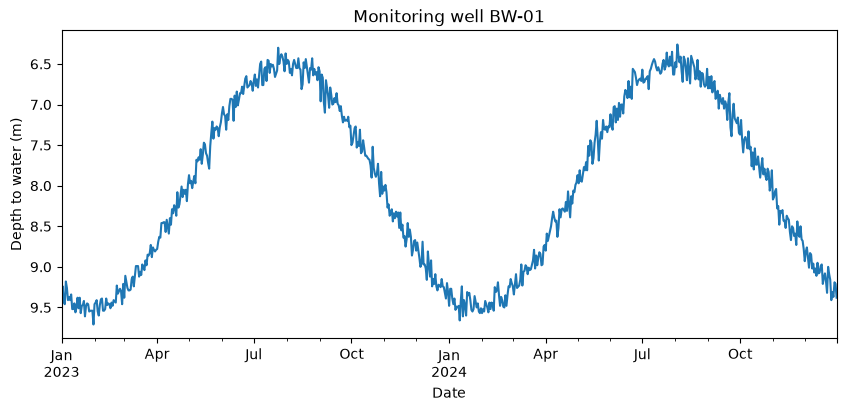

In [9]:
# 4. Plot, with the axis flipped so deeper water plots lower
ax = df["depth_clean"].plot(figsize=(10, 4))
ax.set_ylabel("Depth to water (m)")
ax.set_xlabel("Date")
ax.set_title("Monitoring well BW-01")
ax.invert_yaxis()